### 1. Import das bibliotecas e definição da função de leitura

In [ ]:
import requests
import pandas as pd

def read_ckan_sql(resource_id):
    url = "https://dados.uffs.edu.br/api/3/action/datastore_search_sql"

    limit = 1000
    offset = 0
    all_records = []

    while True:
        sql = f'''
        SELECT *
        FROM "{resource_id}"
        LIMIT {limit}
        OFFSET {offset}
        '''

        response = requests.get(url, params={"sql": sql})
        data = response.json()

        records = data["result"]["records"]

        if not records:
            break

        all_records.extend(records)
        offset += limit

        print(f"Baixados: {offset}")

    df = pd.DataFrame(all_records)
    return df

### 2. Passa o id dos dados pra função de leitura, e transforma o resultado em um dataframe pandas

In [ ]:
df_projetos_extensao = read_ckan_sql("59b793c5-24c3-4437-af34-d2a29f016703")
print("Número de registros:", len(df_projetos_extensao))

Baixados: 1000
Baixados: 2000
Baixados: 3000
Número de registros: 2407


### 3. Mostra os 5 primeiros registros

In [3]:
df_projetos_extensao.head()

,_id,_full_text,projeto_registro,projeto_titulo,data_inicio,data_fim,quant_coordenadores,coordenadores,nome_campus,desc_area_cnpq,palavras_chave,resumo,modalidade,quant_cursos_envolvidos,ids_cursos_envolvidos,nomes_cursos_envolvidos,situacao_projeto,area_tematica,linha,data_atualizacao
0,1,"'-04':14,17,233 '-06':234 '-09':15 '-11':18 '-...",EXT-2026-72,I Encontro Sul de Clínica Médica e Produção Eq...,2026-04-09,2026-04-11,1,DALILA MOTER BENVEGNU,Realeza,MEDICINA VETERINÁRIA,Cavalo; Clínica de grandes animais; Equideocul...,A realização de eventos acadêmicos e científic...,EVENTO,1,3530,MEDICINA VETERINÁRIA - INTEGRAL [REALEZA],PROPOSTA_AVALIACAO,Saúde,Saúde animal,2026-04-06T02:30:15.133935
1,2,"'-01':25 '-04':21,24,345 '-06':346 '-07':22 '-...",EXT-2026-71,Bioinsumos no campo: Formação e qualificação d...,2026-04-07,2035-04-01,1,ANDRE LUIZ RADUNZ,Chapecó,AGRONOMIA,Bioinsumos; Formação e qualificação; Treinamentos,A utilização de bioinsumos apresenta uma cresc...,PROGRAMA,1,1501,AGRONOMIA - MATUTINO [CHAPECÓ],PROPOSTA_AVALIACAO,Educação,Inovação tecnológica,2026-04-06T02:30:15.133935
2,3,"'-04':13,320 '-06':16,17,321 '-07':14 '-2026':...",EXT-2026-70,Bioinsumos no campo: Uso no manejo de sistemas,2026-04-07,2030-06-06,1,ANDRE LUIZ RADUNZ,Chapecó,AGRONOMIA,Bioinsumos; Biologicos; microrganismos solubil...,A utilização de bioinsumos apresenta uma cresc...,PROJETO,1,1501,AGRONOMIA - MATUTINO [CHAPECÓ],PROPOSTA_AVALIACAO,Tecnologia e produção,Inovação tecnológica,2026-04-06T02:30:15.133935
3,4,"'-01':15 '-04':14,772 '-06':773 '-10':17 '-202...",EXT-2026-69,XVI JORNADA DE INICIAÇÃO CIENTÍFICA E TECNOLÓG...,2026-04-01,2026-10-31,1,JOAO PAULO BENDER,Reitoria,EDUCAÇÃO,Ciência e Tecnologia; Iniciação Científica e T...,Descrição: A iniciação científica e tecnológic...,EVENTO,0,NaN,NaN,PROPOSTA_AVALIACAO,Multidisciplinar,Desenvolvimento tecnológico,2026-04-06T02:30:15.133935
4,5,"'-04':12,15,210 '-06':211 '-07':13,16 '-2026':...",EXT-2026-68,Formação Continuada “Aperfeiçoamento em Pré-Na...,2026-04-07,2026-04-07,1,LEANDRO TUZZIN,Passo Fundo,MEDICINA,atenção primária à saúde; pré-natal; saúde da ...,A atividade de ensino Formação Continuada “Ape...,EVENTO,2,6401; 6400,ENFERMAGEM - INTEGRAL [PASSO FUNDO]; MEDICINA ...,PROPOSTA_AVALIACAO,Saúde,Saúde da família,2026-04-06T02:30:15.133935


### 4. Leitura do dicionário de dados do arquivo

In [4]:
df_dicionario_dados = read_ckan_sql("3b515999-b34e-4f0e-b0b2-b6d4ddfdefd0")
print("Número de registros:", len(df_dicionario_dados))

Baixados: 1000
Número de registros: 18


### 5. Mostra os registros

In [5]:
df_dicionario_dados

,_id,_full_text,coluna,tipo,rotulo,descricao
0,1,'ano':20 'cul/ens/ext/pes':19 'exceçã':31 'for...,projeto_registro,text,Nº Registro,Número de Registro do projeto no sistema Prism...
1,2,"'projet':1,7 'text':3 'titul':2 'títul':4,5",projeto_titulo,text,Título,Título do Projeto.
2,3,"'comec':12 'dat':1,3,4,7 'inic':17 'inici':2 '...",data_inicio,date,Data de Início,Data em que o projeto começou ou em pretende s...
3,4,"'dat':1,3,4,7 'encerr':19 'fim':2 'prev':17 'p...",data_fim,date,Data de Término,Data em que o projeto terminou ou em que se pr...
4,5,"'cooorden':6 'coorden':2,9,18 'integ':3 'men':...",quant_coordenadores,integer,Quantidade de Cooordenadores,Quantidade de coordenadores do projeto. Todo p...
5,6,"'coorden':1,3,8 'nom':4 'pont':13 'projet':10 ...",coordenadores,text,Coordenadores,"Nome de todos os coordenadores do projeto, sep..."
6,7,"'camp':16 'campus':2,4,5 'criaçã':8,26 'envolv...",nome_campus,text,Campus,Campus responsável pela criação do projeto. Um...
7,8,"'are':2 'cnpq':3,7,16 'conhec':10 'desc':1 'gr...",desc_area_cnpq,text,Grande Área CNPq,Área de conhecimento do projeto em relação ao ...
8,9,"'chav':2,6,9 'palavr':1,5,8 'palavras-chav':4,...",palavras_chave,text,Palavras-chave,Palavras-chave relacionadas ao projeto.
9,10,'descriçã':4 'objet':16 'projet':11 'qua':13 '...,resumo,text,Resumo,Descrição sucinta sobre o que trata o projeto ...


### Funções úteis

In [6]:
# 1. Função para formatar o número no padrão moeda do Brasil
from pandas.io.formats.style import Styler
def formatar_moeda_br(valor):
    if pd.isna(valor):
        return "R$ 0,00"
    
    # Formata com 2 casas decimais no padrão americano (ex: 1,234,567.89)
    valor_str = f"{valor:,.2f}"
    
    # Troca a vírgula por um 'X' temporário, o ponto por vírgula, e o 'X' por ponto
    valor_br = valor_str.replace(",", "X").replace(".", ",").replace("X", ".")
    
    return f"R$ {valor_br}"

## Análises iniciais

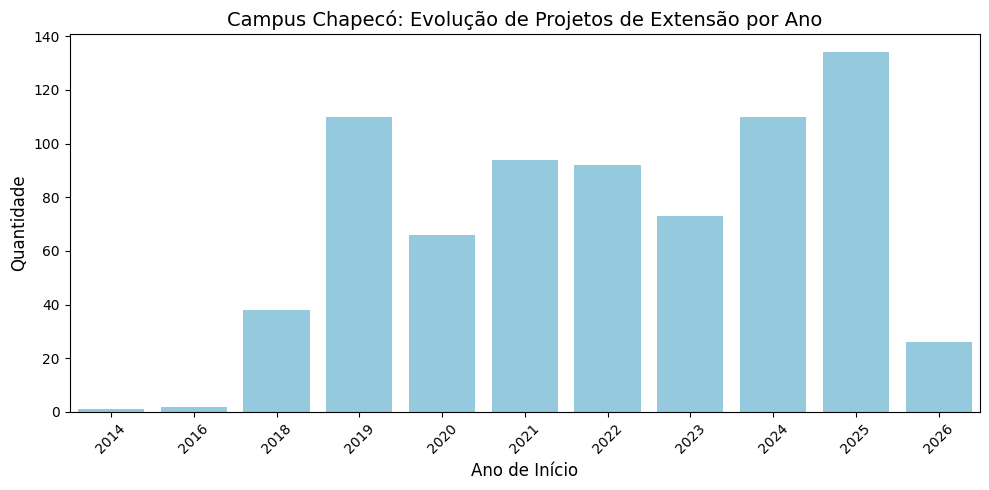

Duração média dos projetos em Chapecó: 557 dias (Aprox. 18.6 meses)


C:\Users\marco\AppData\Local\Temp\ipykernel_15828\3928563851.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=situacao_counts.values, y=situacao_counts.index, palette='viridis')


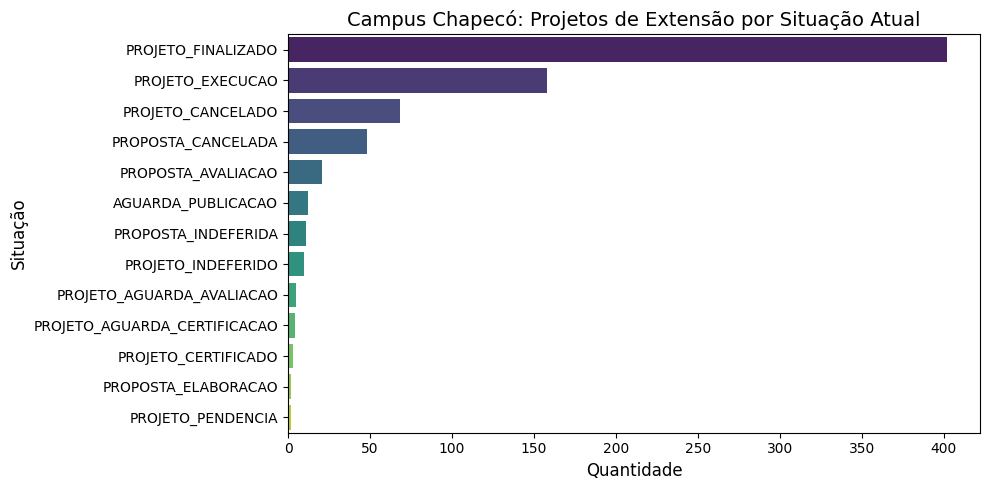

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 0. A Mágica do Escopo (Filtrando apenas Chapecó)
# Assumindo que seu DataFrame original chama df_projetos_extensao
df_chapeco = df_projetos_extensao[df_projetos_extensao['nome_campus'] == 'Chapecó'].copy()

# 1. Pré-processamento das datas
df_chapeco['data_inicio'] = pd.to_datetime(df_chapeco['data_inicio'], errors='coerce')
df_chapeco['data_fim'] = pd.to_datetime(df_chapeco['data_fim'], errors='coerce')

# Extraindo o ano de início
df_chapeco['ano_inicio'] = df_chapeco['data_inicio'].dt.year

# 2. Projetos por Ano em Chapecó (Crescimento/Sazonalidade)
plt.figure(figsize=(10, 5))
df_ano = df_chapeco[(df_chapeco['ano_inicio'] >= 2010) & (df_chapeco['ano_inicio'] <= 2026)]
sns.countplot(data=df_ano, x='ano_inicio', color='skyblue')
plt.title('Campus Chapecó: Evolução de Projetos de Extensão por Ano', fontsize=14)
plt.xlabel('Ano de Início', fontsize=12)
plt.ylabel('Quantidade', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Duração Média dos Projetos em Chapecó
df_chapeco['duracao_dias'] = (df_chapeco['data_fim'] - df_chapeco['data_inicio']).dt.days
duracao_media = df_chapeco[df_chapeco['duracao_dias'] > 0]['duracao_dias'].mean()
print(f"Duração média dos projetos em Chapecó: {duracao_media:.0f} dias (Aprox. {duracao_media/30:.1f} meses)")

# 4. Situação dos Projetos em Chapecó (Taxa de Conclusão)
plt.figure(figsize=(10, 5))
situacao_counts = df_chapeco['situacao_projeto'].value_counts()
sns.barplot(x=situacao_counts.values, y=situacao_counts.index, palette='viridis')
plt.title('Campus Chapecó: Projetos de Extensão por Situação Atual', fontsize=14)
plt.xlabel('Quantidade', fontsize=12)
plt.ylabel('Situação', fontsize=12)
plt.tight_layout()
plt.show()

C:\Users\marco\AppData\Local\Temp\ipykernel_15828\3802621300.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=area_counts.values, y=area_counts.index, palette='magma')


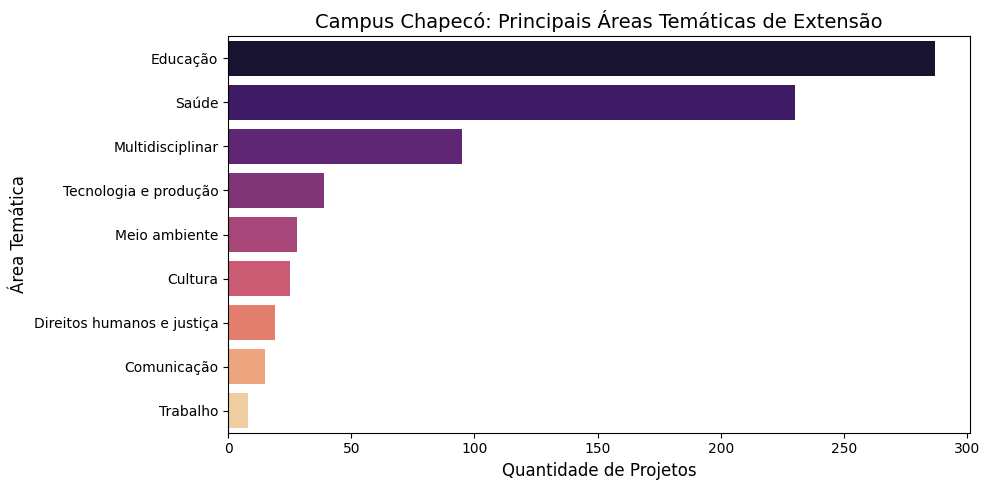

C:\Users\marco\AppData\Local\Temp\ipykernel_15828\3802621300.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_coordenadores.values, y=top_coordenadores.index, palette='crest')


Média de coordenadores por projeto em Chapecó: 1.11 pessoas


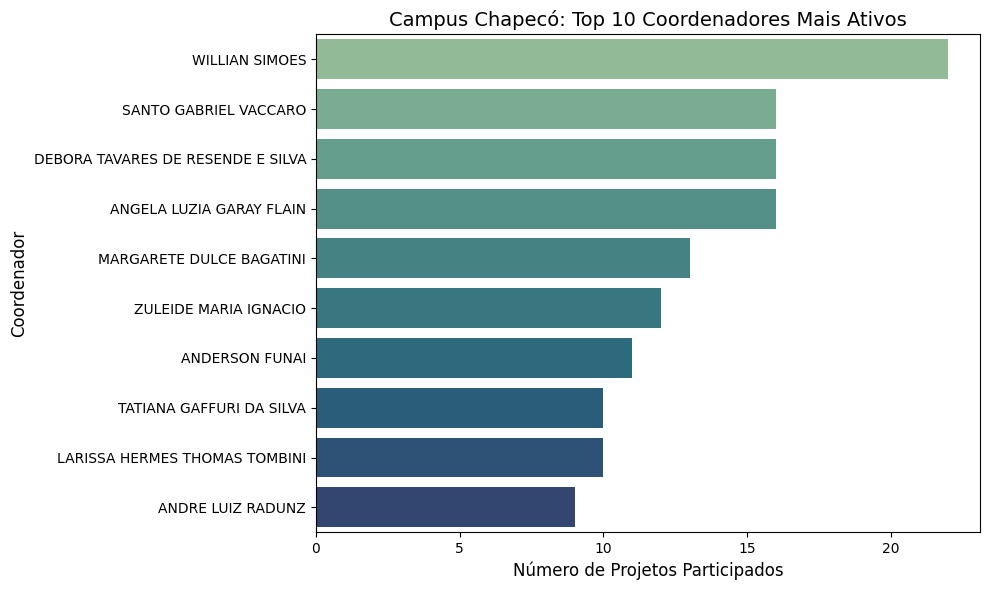

In [10]:
# 1. Vocação de Chapecó (Áreas Temáticas)
plt.figure(figsize=(10, 5))
area_counts = df_chapeco['area_tematica'].value_counts()
sns.barplot(x=area_counts.values, y=area_counts.index, palette='magma')
plt.title('Campus Chapecó: Principais Áreas Temáticas de Extensão', fontsize=14)
plt.xlabel('Quantidade de Projetos', fontsize=12)
plt.ylabel('Área Temática', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Média de Coordenadores por Projeto (Tamanho da Liderança local)
df_chapeco['quant_coordenadores'] = pd.to_numeric(df_chapeco['quant_coordenadores'], errors='coerce')
media_coords = df_chapeco['quant_coordenadores'].mean()
print(f"Média de coordenadores por projeto em Chapecó: {media_coords:.2f} pessoas")

# 3. Engajamento: Top 10 Coordenadores de Chapecó
# Como os nomes vêm separados por ';', precisamos quebrar (explode) a coluna
coord_series = df_chapeco['coordenadores'].dropna().str.split(';').explode().str.strip()
top_coordenadores = coord_series.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_coordenadores.values, y=top_coordenadores.index, palette='crest')
plt.title('Campus Chapecó: Top 10 Coordenadores Mais Ativos', fontsize=14)
plt.xlabel('Número de Projetos Participados', fontsize=12)
plt.ylabel('Coordenador', fontsize=12)
plt.tight_layout()
plt.show()